In [8]:
import csv
import io
import re
import time
import zipfile
from dataclasses import dataclass, field
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize, LinearConstraint, Bounds

from sympy import symbols, lambdify, sympify
from sympy.parsing.sympy_parser import parse_expr

from common_libs import check_vector,show_iteration_table, plot_convergence


### Ví dụ kiểm thử bốn thuật toán FBM, MFBSM, RFBSM và IRFBSM

Xét bài toán bao hàm biến phân:

$$
0\in A(x)+B(x),
$$

trong đó:

$$
A(x)=0,\qquad B(x)=Qx,
$$

với:

$$
Q=
\begin{pmatrix}
0.01 & 0\\
0 & 1
\end{pmatrix}.
$$

Do $A=0$, toán tử giải là ánh xạ đồng nhất:

$$
J_{\gamma A}(z)=z.
$$

Nghiệm chính xác của bài toán là:

$$
\boxed{x^*=(0,0)^\top.}
$$

Các tham số thực nghiệm được lựa chọn:

- Điểm khởi tạo: $x^{-1}=x^0=(1,1)^\top$.
- Cỡ bước ban đầu: $\gamma_0=0.4$.
- Tham số nới lỏng: $\theta=0.8$.
- Tham số cập nhật cỡ bước: $\mu=0.9$.
- Tham số quán tính: $\alpha=0.1$.
- Số vòng lặp tối đa: `max_iter = 10000`.
- Ngưỡng sai số: `tol = 1e-8`.

Cả bốn thuật toán sử dụng cùng tiêu chuẩn dừng:

$$
\boxed{\|x^{k+1}-x^k\|_2\leq 10^{-8}.}
$$

Mục tiêu của ví dụ là kiểm tra tính đúng đắn của chương trình và so sánh quá trình hội tụ của bốn thuật toán trước khi áp dụng trên dữ liệu tài chính thực tế.


In [9]:
Q = np.array([
    [0.01, 0.0],
    [0.0, 1.0]
])

def B(x):
    return Q @ x

def prox(z, gamma):
    return z

x0 = np.array([1.0, 1.0])
x_minus1 = x0.copy()

gamma = 0.4
theta = 0.8
mu = 0.9
alpha = 0.1

max_iter = 10000
tol = 1e-8
iter_list = (1, 10, 100, 1000, 10000)

# THUẬT TOÁN FORWARD-BACKWARD SPLITTING METHOD (FBM)

Điều kiện FBM:

- $A$ là toán tử đa trị đơn điệu cực đại (tồn tại resolvent)
- $B$ là toán tử đơn trị thường được giả thiết $\beta$ cocoercive
- $J_{\gamma A} = (I + \gamma A)^{-1}$ là toán tử giải của A
- $\gamma > 0$ là cỡ bước ($0<\gamma<2\beta$)

### Mã giả Forward–Backward Splitting Method (FBM)

**Bước 0 (Khởi tạo).**

Chọn điểm ban đầu $x^0\in\mathcal H$, cỡ bước $\gamma\in(0,2\beta)$, trong đó $B$ là toán tử $\beta$-cocoercive.

Đặt $k=0$.

**Bước 1.** Tính điểm trung gian:

$$
y^k=x^k-\gamma B(x^k).
$$

**Bước 2.** Tính điểm lặp tiếp theo:

$$
x^{k+1}=J_{\gamma A}(y^k).
$$

**Bước 3.** Đặt $k:=k+1$ và quay lại Bước 1.

In [10]:
from FBM import fbm

result_fbm = fbm(
    x0, B, prox, gamma,
    max_iter=max_iter,
    tol=tol,
    iter_list=iter_list
)

show_iteration_table(result_fbm)


,Iteration (k),x^k (vector),Residual ||x^k - x^(k-1)||₂,Final
0,0,"[1., 1.]",—,False
1,1,"[0.996, 0.6 ]",4.000e-01,False
2,10,"[0.96071237, 0.00604662]",5.580e-03,False
3,100,"[6.69782571e-01, 6.53318624e-23]",2.690e-03,False
4,1000,"[1.81693095e-002, 1.41661026e-222]",7.297e-05,False
5,3220,"[2.48353179e-006, 4.94065646e-324]",9.974e-09,True


,Iteration (k),x^k (vector),Residual ||x^k - x^(k-1)||₂,Final
0,0,"[1., 1.]",—,False
1,1,"[0.996, 0.6 ]",4.000e-01,False
2,10,"[0.96071237, 0.00604662]",5.580e-03,False
3,100,"[6.69782571e-01, 6.53318624e-23]",2.690e-03,False
4,1000,"[1.81693095e-002, 1.41661026e-222]",7.297e-05,False
5,3220,"[2.48353179e-006, 4.94065646e-324]",9.974e-09,True


# THUẬT TOÁN MODIFIED FORWARD–BACKWARD SPLITTING METHOD (MFBSM) CỦA TSENG

Điều kiện MFBSM:

- $A$ là toán tử đa trị đơn điệu cực đại (tồn tại resolvent).
- $B$ là toán tử đơn trị, đơn điệu và liên tục Lipschitz với hằng số $L>0$.
- Tập nghiệm $(A+B)^{-1}(0)$ khác rỗng.
- $J_{\alpha_k A}=(I+\alpha_k A)^{-1}$ là toán tử giải của $A$.
- $\alpha_k>0$ là cỡ bước, với dãy $\{\alpha_k\}$ thỏa mãn:

$$
\{\alpha_k\}\subset[a,b]\subset\left(0,\frac1L\right).
$$

Khác với FBM thông thường, MFBSM không yêu cầu toán tử $B$ phải cocoercive mà chỉ cần đơn điệu và liên tục Lipschitz.


### Mã giả Modified Forward–Backward Splitting Method (MFBSM_Tseng)

**Bước 0 (Khởi tạo).**

Chọn điểm ban đầu $x^0\in\mathcal H$, dãy cỡ bước $\{\alpha_k\}\subset[a,b]\subset(0,1/L)$, trong đó $B$ là toán tử đơn điệu và liên tục Lipschitz với hằng số $L>0$.

Đặt $k=0$.

**Bước 1.** Tính điểm trung gian:

$$
z^k=x^k-\alpha_k B(x^k).
$$

**Bước 2.** Tính:

$$
y^k=J_{\alpha_k A}(z^k).
$$

**Bước 3.** Thực hiện bước hiệu chỉnh:

$$
x^{k+1}
=
y^k-\alpha_k\left(B(y^k)-B(x^k)\right).
$$

**Bước 4.** Đặt $k:=k+1$ và quay lại Bước 1.

In [11]:
from MFBSM_Tseng import mfbm_tseng

result_mfbm = mfbm_tseng(
    x0, B, prox, gamma,
    max_iter=max_iter,
    tol=tol,
    iter_list=iter_list
)

show_iteration_table(result_mfbm)

,Iteration (k),x^k (vector),Residual ||x^k - x^(k-1)||₂,Final
0,0,"[1., 1.]",—,False
1,1,"[0.996016, 0.76 ]",2.400e-01,False
2,10,"[0.96086672, 0.06428889]",2.066e-02,False
3,100,"[6.70859383e-01, 1.20603310e-12]",2.683e-03,False
4,1000,"[1.84635406e-002, 6.51016927e-120]",7.385e-05,False
5,3232,"[2.49304452e-006, 4.94065646e-324]",9.972e-09,True


,Iteration (k),x^k (vector),Residual ||x^k - x^(k-1)||₂,Final
0,0,"[1., 1.]",—,False
1,1,"[0.996016, 0.76 ]",2.400e-01,False
2,10,"[0.96086672, 0.06428889]",2.066e-02,False
3,100,"[6.70859383e-01, 1.20603310e-12]",2.683e-03,False
4,1000,"[1.84635406e-002, 6.51016927e-120]",7.385e-05,False
5,3232,"[2.49304452e-006, 4.94065646e-324]",9.972e-09,True



# THUẬT TOÁN RELAXED FORWARD–BACKWARD SPLITTING METHOD (RFBSM)

**Điều kiện RFBSM:**

- $A:\mathcal H\to 2^{\mathcal H}$ là toán tử đa trị đơn điệu cực đại.
- $B:\mathcal H\to\mathcal H$ là toán tử đơn trị, đơn điệu và liên tục Lipschitz với hằng số $L>0$.
- Tập nghiệm $\Omega=(A+B)^{-1}(0)\neq\varnothing$.
- $J_{\gamma_k A}=(I+\gamma_k A)^{-1}$ là toán tử giải của $A$.
- $\gamma_0>0$ là cỡ bước khởi tạo.
- $\{\theta_k\}\subset[a,b]\subset(0,1]$ là dãy tham số nới lỏng.
- $\{\mu_k\}\subset[c,d]\subset(0,1)$ là dãy tham số điều khiển cỡ bước.

### Mã giả Relaxed Forward–Backward Splitting Method (RFBSM)

**Bước 0 (Khởi tạo).**

Chọn điểm ban đầu $x^0\in\mathcal H$, cỡ bước $\gamma_0>0$, hai dãy tham số $\{\theta_k\}\subset[a,b]\subset(0,1]$ và $\{\mu_k\}\subset[c,d]\subset(0,1)$.

Đặt $k=0$.

**Bước 1.** Tính điểm trung gian:

$$
y^k=J_{\gamma_k A}(x^k-\gamma_k B(x^k)).
$$

**Bước 2.** Tính điểm lặp tiếp theo:

$$
x^{k+1}=(1-\theta_k)x^k+\theta_k y^k
+\theta_k\gamma_k\big(B(x^k)-B(y^k)\big).
$$

**Bước 3.** Cập nhật cỡ bước:

$$
\gamma_{k+1}=
\begin{cases}
\displaystyle
\min\left\{\gamma_k,
\frac{\mu_k\|x^k-y^k\|}
{\|B(x^k)-B(y^k)\|}\right\},
& B(x^k)\neq B(y^k),\\[10pt]
\gamma_k,
& B(x^k)=B(y^k).
\end{cases}
$$

**Bước 4.** Đặt $k:=k+1$ và quay lại Bước 1.


In [12]:
from RMFBSM import rmfbsm

result_rmfbsm = rmfbsm(
    x0, B, prox, gamma, theta, mu,
    max_iter=max_iter,
    tol=tol,
    iter_list=iter_list
)

show_iteration_table(result_rmfbsm)

,Iteration (k),x^k (vector),Residual ||x^k - x^(k-1)||₂,Gamma,Final
0,0,"[1., 1.]",—,4.000000e-01,False
1,1,"[0.9968128, 0.808 ]",1.920e-01,4.000000e-01,False
2,10,"[0.96858126, 0.1186079 ]",2.835e-02,4.000000e-01,False
3,100,"[7.26709118e-01, 5.50980308e-10]",2.324e-03,4.000000e-01,False
4,1000,"[4.10776977e-02, 2.57846223e-93]",1.313e-04,4.000000e-01,False
5,3971,"[3.12341579e-006, 1.97626258e-323]",9.987e-09,4.000000e-01,True


,Iteration (k),x^k (vector),Residual ||x^k - x^(k-1)||₂,Gamma,Final
0,0,"[1., 1.]",—,4.000000e-01,False
1,1,"[0.9968128, 0.808 ]",1.920e-01,4.000000e-01,False
2,10,"[0.96858126, 0.1186079 ]",2.835e-02,4.000000e-01,False
3,100,"[7.26709118e-01, 5.50980308e-10]",2.324e-03,4.000000e-01,False
4,1000,"[4.10776977e-02, 2.57846223e-93]",1.313e-04,4.000000e-01,False
5,3971,"[3.12341579e-006, 1.97626258e-323]",9.987e-09,4.000000e-01,True



# THUẬT TOÁN INERTIAL RELAXED FORWARD–BACKWARD SPLITTING METHOD (IRFBSM)

### Điều kiện IRFBSM

- $A$ là toán tử đa trị đơn điệu cực đại.
- $B$ là toán tử đơn trị, đơn điệu và liên tục Lipschitz.
- Tập nghiệm $(A+B)^{-1}(0)\neq\varnothing$.
- $J_{\gamma A}=(I+\gamma A)^{-1}$ là toán tử giải của $A$.
- $\gamma_0>0$ là cỡ bước khởi tạo.
- $\theta\in(0,1]$ là tham số nới lỏng.
- $\mu\in(0,1)$ là tham số cập nhật cỡ bước.
- $\alpha\in[0,1)$ là tham số quán tính, thỏa mãn:

$$
\frac{\theta(1-\mu^2)}{(2-\theta+\mu\theta)^2}
+\frac{1-\theta}{\theta}
>
\frac{\alpha(1+\alpha)}{(1-\alpha)^2}.
$$

### Mã giả Inertial Relaxed Forward–Backward Splitting Method (IRFBSM)

**Bước 0 (Khởi tạo).**

Chọn hai điểm ban đầu $x^{-1},x^0\in\mathcal H$, cỡ bước $\gamma_0>0$ và các tham số $\theta,\mu,\alpha$ thỏa mãn các điều kiện trên.

Đặt $k=0$.

**Bước 1.** Tính điểm quán tính:

$$
w^k=x^k+\alpha(x^k-x^{k-1}).
$$

Sau đó tính điểm trung gian:

$$
y^k=J_{\gamma_k A}(w^k-\gamma_k B(w^k)).
$$

**Bước 2.** Tính điểm lặp tiếp theo:

$$
x^{k+1}
=(1-\theta)w^k+\theta y^k
+\theta\gamma_k\big(B(w^k)-B(y^k)\big).
$$

**Bước 3.** Cập nhật cỡ bước:

$$
\gamma_{k+1}=
\begin{cases}
\displaystyle
\min\left\{
\gamma_k,\,
\frac{\mu\|w^k-y^k\|}
{\|B(w^k)-B(y^k)\|}
\right\},
& B(w^k)\neq B(y^k),\\[10pt]
\gamma_k,
& B(w^k)=B(y^k).
\end{cases}
$$

**Bước 4.** Đặt $k:=k+1$ và quay lại Bước 1.


In [13]:
from IRFBSM import irfbsm

result_irfbsm = irfbsm(
    x_minus1, x0, B, prox,
    gamma, theta, mu, alpha,
    max_iter=max_iter,
    tol=tol,
    iter_list=iter_list
)

show_iteration_table(result_irfbsm)

,Iteration (k),x^k (vector),Residual ||x^k - x^(k-1)||₂,Gamma,Final
0,0,"[1., 1.]",—,4.000000e-01,False
1,1,"[0.9968128, 0.808 ]",1.920e-01,4.000000e-01,False
2,10,"[0.96552579, 0.0928957 ]",2.552e-02,4.000000e-01,False
3,100,"[7.01607758e-01, 3.59818080e-11]",2.494e-03,4.000000e-01,False
4,1000,"[2.88004587e-002, 2.73499613e-105]",1.024e-04,4.000000e-01,False
5,3603,"[2.81040799e-006, 1.97626258e-323]",9.988e-09,4.000000e-01,True


,Iteration (k),x^k (vector),Residual ||x^k - x^(k-1)||₂,Gamma,Final
0,0,"[1., 1.]",—,4.000000e-01,False
1,1,"[0.9968128, 0.808 ]",1.920e-01,4.000000e-01,False
2,10,"[0.96552579, 0.0928957 ]",2.552e-02,4.000000e-01,False
3,100,"[7.01607758e-01, 3.59818080e-11]",2.494e-03,4.000000e-01,False
4,1000,"[2.88004587e-002, 2.73499613e-105]",1.024e-04,4.000000e-01,False
5,3603,"[2.81040799e-006, 1.97626258e-323]",9.988e-09,4.000000e-01,True


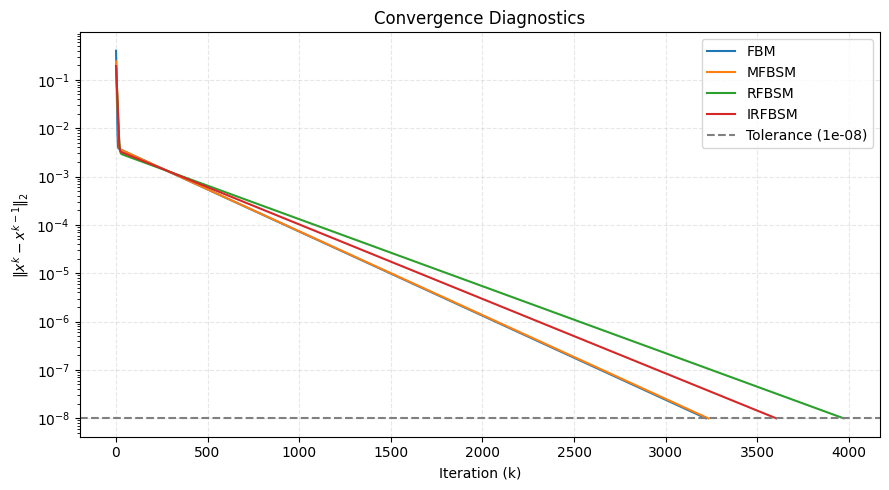

In [14]:
results = {
    "FBM": result_fbm,
    "MFBSM": result_mfbm,
    "RFBSM": result_rmfbsm,
    "IRFBSM": result_irfbsm
}

plot_convergence(results, tol=1e-8)